# EXP-006: Gradient-DIRECTION-consistency diagnostic -- does it catch label noise where magnitude-based signals missed it?

**Status: engineering validation / proof of concept**, same caveats as prior notebooks.

**Purpose**: EXP-005 showed that neither gradient-norm MEAN nor gradient-norm
VARIANCE catches label noise, because flipped labels corrupt gradient DIRECTION for a
random subset of samples without inflating any individual gradient's MAGNITUDE. This
notebook tests the natural next signal: **consecutive-step gradient DIRECTION
consistency** (cosine similarity between the full gradient vector at step t and at
step t-1). Hypothesis: under a stable task, batch-to-batch gradients should point in
fairly consistent directions (different samples, same underlying decision boundary to
correct toward); label noise should make this LESS consistent, because a randomly
different subset of "wrong-direction" samples pollutes each batch.

**Important framing, decided BEFORE running anything**: this tests whether direction-
consistency can DETECT that something is different about label noise, not whether
"reduce" becomes empirically correct for it -- EXP-003/004 already established that
"increase" is the correct answer for label noise, decisively and by a growing margin.
If this diagnostic successfully flags label noise as unusual, that is a detection
capability, not a licence to conclude "reduce" is now right for label noise. Both are
tracked separately below.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task, all three disturbance types, direction-consistency diagnostic

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, drift_frac=0.0, flip_prob=0.0, batch_size=16):
    frac = float(np.clip(drift_frac, 0.0, 1.0))
    mean0 = (1 - frac) * MEAN0_BASE + frac * MEAN1_BASE
    mean1 = (1 - frac) * MEAN1_BASE + frac * MEAN0_BASE
    y_true = rng.integers(0, 2, size=batch_size)
    means = np.where(y_true[:, None] == 0, mean0, mean1)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    flip_mask = rng.random(batch_size) < flip_prob
    y_observed = np.where(flip_mask, 1 - y_true, y_true)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y_observed, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5

def flat_grad(model):
    return torch.cat([p.grad.detach().flatten() for p in model.parameters() if p.grad is not None])

def cos_sim(a, b):
    denom = (a.norm() * b.norm()).item() + 1e-8
    return float(torch.dot(a, b).item() / denom)

N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
WARMUP = 50
TREND_WINDOW = 5
DIR_WINDOW = 15              # trailing window of consecutive-step cosine similarities
STEADY_STATE_WINDOW = 100
GRAD_NOISE_MAX = 8.0
LABEL_FLIP_PROB = 0.35
CALIB_START, CALIB_END = 150, 200   # R3-corrected post-convergence calibration window

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def drift_forecastable(step):
    return (_ramp(step), 0.0, 0.0)

def drift_unforecastable(step):
    return (_instant(step), 0.0, 0.0)

def instability_forecastable(step):
    return (0.0, GRAD_NOISE_MAX * _ramp(step), 0.0)

def instability_unforecastable(step):
    return (0.0, GRAD_NOISE_MAX * _instant(step), 0.0)

def label_noise_forecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _ramp(step))

def label_noise_unforecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _instant(step))

GRAD_RATIO_SENSITIVITY = 1.5
DIR_RATIO_SENSITIVITY = 1.5

def auto_select_intervention_grad(loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean,
                                   sensitivity=GRAD_RATIO_SENSITIVITY):
    '''MEAN-based (EXP-001/002).'''
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_ratio = (float(np.mean(gradnorm_window)) + 1e-6) / (baseline_gradnorm_mean + 1e-6)
    return "reduce" if gradnorm_ratio > sensitivity * loss_ratio else "increase"

DIR_Z_THRESHOLD = 2.0

def auto_select_intervention_cossim(cossim_window, baseline_cossim, baseline_cossim_std,
                                     z_threshold=DIR_Z_THRESHOLD):
    '''DIRECTION-based. Cosine similarity between consecutive gradient vectors, averaged
    over a trailing window, compared to its OWN warmup baseline mean/std (a z-score),
    NOT to a loss-ratio-scaled threshold.

    R7 FIX (2026-08-26, revision roadmap): the original version compared a "drop_ratio"
    -- bounded by construction, since cos-sim lives in [-1,1] -- against
    `sensitivity * loss_ratio`, where loss_ratio is UNBOUNDED and grows large (5-20x)
    under exactly the disturbances this diagnostic is meant to catch. That made the
    fire condition mathematically close to impossible under any real disturbance: a
    naturally-capped statistic can never out-grow an unbounded one once loss is
    substantially elevated (Domain/Devil's Advocate, Critical). The fix decouples the
    decision from loss_ratio entirely and instead asks the question the diagnostic is
    actually meant to answer -- "has direction-consistency moved further from ITS OWN
    baseline than its OWN baseline noise would predict?" -- the same z-score structure
    already used successfully by the val-gap diagnostic (EXP-008).'''
    current_cossim = float(np.mean(cossim_window))
    z = (baseline_cossim - current_cossim) / (baseline_cossim_std + 1e-6)
    return "reduce" if z > z_threshold else "increase"


## 2. Single training run (arm C, tracks mean-based AND direction-based diagnostics)

In [3]:
def run_trial(seed, disturbance_fn):
    '''Diagnostic-only, like EXP-005 -- no LR actually varied. Reports what each
    diagnostic WOULD say at the loss-based trigger point.'''
    rng = np.random.default_rng(seed)
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist, cossim_hist = [], [], []
    prev_grad = None
    threshold = baseline_loss_mean = baseline_gradnorm_mean = None
    baseline_cossim = baseline_cossim_std = None

    for step in range(N_STEPS):
        drift_frac, grad_noise_extra, flip_prob = disturbance_fn(step)
        xb, yb = gen_batch(rng, drift_frac=drift_frac, flip_prob=flip_prob)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        if grad_noise_extra > 0:
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.grad.add_(torch.randn_like(p.grad) * grad_noise_extra)
        gn_t = grad_norm(model)

        cur_grad = flat_grad(model)
        if prev_grad is not None:
            cossim_hist.append(cos_sim(cur_grad, prev_grad))
        else:
            cossim_hist.append(1.0)  # no prior step to compare on step 0
        prev_grad = cur_grad

        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)

        if step == CALIB_END - 1:
            calib_loss = np.array(loss_hist[CALIB_START:CALIB_END])
            calib_gradnorm = np.array(gradnorm_hist[CALIB_START:CALIB_END])
            calib_cossim = np.array(cossim_hist[CALIB_START:CALIB_END])
            threshold = float(calib_loss.mean() + 3 * calib_loss.std() + 1e-6)
            baseline_loss_mean = float(calib_loss.mean())
            baseline_gradnorm_mean = float(calib_gradnorm.mean())
            baseline_cossim = float(calib_cossim.mean())
            baseline_cossim_std = float(calib_cossim.std()) + 1e-6

        if step >= CALIB_END and threshold is not None and loss_t > threshold:
            loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            cossim_window = cossim_hist[max(0, step - DIR_WINDOW + 1):step + 1]
            diag_mean = auto_select_intervention_grad(
                loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean)
            diag_dir = auto_select_intervention_cossim(
                cossim_window, baseline_cossim, baseline_cossim_std)
            return {"trigger_step": step, "diag_mean": diag_mean, "diag_dir": diag_dir,
                    "baseline_cossim": baseline_cossim, "window_cossim": float(np.mean(cossim_window))}

        opt.step()

    return {"trigger_step": None, "diag_mean": None, "diag_dir": None,
            "baseline_cossim": baseline_cossim, "window_cossim": None}


## 3. Run all three disturbance types, both conditions, 10 seeds

In [4]:
SEEDS = list(range(10))
CONDITIONS = {
    "drift_forecastable": drift_forecastable, "drift_unforecastable": drift_unforecastable,
    "instability_forecastable": instability_forecastable, "instability_unforecastable": instability_unforecastable,
    "label_noise_forecastable": label_noise_forecastable, "label_noise_unforecastable": label_noise_unforecastable,
}
empirically_correct = {
    "drift_forecastable": "increase", "drift_unforecastable": "increase",
    "instability_forecastable": "reduce", "instability_unforecastable": "reduce",
    "label_noise_forecastable": "increase", "label_noise_unforecastable": "increase",
}

results = []
for cond_name, fn in CONDITIONS.items():
    for seed in SEEDS:
        r = run_trial(seed, fn)
        results.append({
            "condition": cond_name, "seed": seed, "trigger_step": r["trigger_step"],
            "diag_mean": r["diag_mean"], "diag_dir": r["diag_dir"],
            "baseline_cossim": r["baseline_cossim"], "window_cossim": r["window_cossim"],
        })

df = pd.DataFrame(results)
print(f"Total trials: {len(df)}")
df.head(10)


Total trials: 60


,condition,seed,trigger_step,diag_mean,diag_dir,baseline_cossim,window_cossim
0,drift_forecastable,0,206,increase,increase,0.638079,0.736094
1,drift_forecastable,1,207,increase,increase,0.548096,0.438191
2,drift_forecastable,2,202,increase,increase,0.593869,0.568681
3,drift_forecastable,3,208,increase,increase,0.780296,0.836514
4,drift_forecastable,4,206,increase,increase,0.615491,0.664149
5,drift_forecastable,5,201,increase,increase,0.662721,0.745941
6,drift_forecastable,6,207,increase,increase,0.547841,0.458761
7,drift_forecastable,7,208,increase,increase,0.623217,0.658257
8,drift_forecastable,8,205,increase,increase,0.619778,0.515076
9,drift_forecastable,9,207,increase,increase,0.569293,0.582145


## 4. Comparison: does direction-consistency detect label noise as different?

In [5]:
print(f"{'condition':28s}{'n_trig':>8s}{'mean->reduce%':>15s}{'dir->reduce%':>14s}{'base_cossim':>13s}{'window_cossim':>15s}{'empirically correct':>22s}")
rows = []
for cond in CONDITIONS:
    sub = df[(df["condition"] == cond) & df["trigger_step"].notna()]
    n = len(sub)
    mean_reduce_pct = (sub["diag_mean"] == "reduce").mean() * 100 if n else float("nan")
    dir_reduce_pct = (sub["diag_dir"] == "reduce").mean() * 100 if n else float("nan")
    base_cs = sub["baseline_cossim"].mean() if n else float("nan")
    win_cs = sub["window_cossim"].mean() if n else float("nan")
    print(f"{cond:28s}{n:8d}{mean_reduce_pct:15.0f}{dir_reduce_pct:14.0f}{base_cs:13.3f}{win_cs:15.3f}{empirically_correct[cond]:>22s}")
    rows.append({"condition": cond, "n_triggered": n, "mean_reduce_pct": mean_reduce_pct,
                 "dir_reduce_pct": dir_reduce_pct, "baseline_cossim": base_cs, "window_cossim": win_cs,
                 "empirically_correct": empirically_correct[cond]})
comparison = pd.DataFrame(rows)


condition                     n_trig  mean->reduce%  dir->reduce%  base_cossim  window_cossim   empirically correct
drift_forecastable                10              0             0        0.620          0.620              increase
drift_unforecastable              10              0             0        0.620          0.584              increase
instability_forecastable          10            100            10        0.620          0.163                reduce
instability_unforecastable        10            100             0        0.620          0.558                reduce
label_noise_forecastable          10              0             0        0.620          0.630              increase
label_noise_unforecastable        10              0             0        0.620          0.577              increase


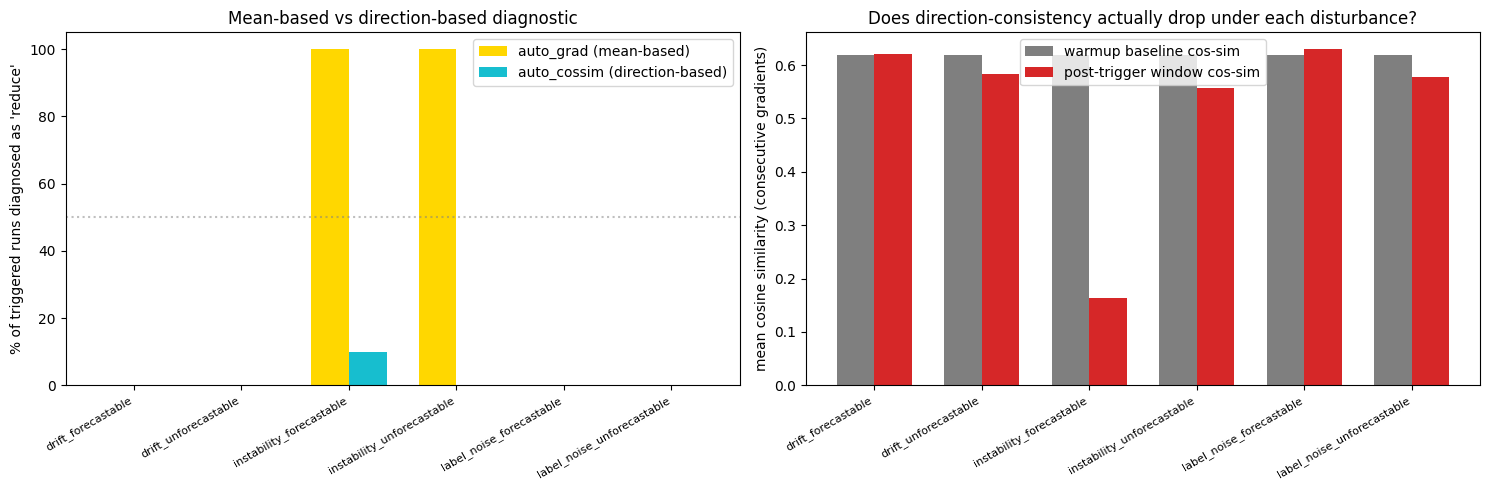

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(comparison))
width = 0.35
axes[0].bar(x - width/2, comparison["mean_reduce_pct"], width, label="auto_grad (mean-based)", color="gold")
axes[0].bar(x + width/2, comparison["dir_reduce_pct"], width, label="auto_cossim (direction-based)", color="tab:cyan")
axes[0].axhline(50, color="gray", linestyle=":", alpha=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison["condition"], rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("% of triggered runs diagnosed as 'reduce'")
axes[0].set_title("Mean-based vs direction-based diagnostic")
axes[0].legend()

axes[1].bar(x - width/2, comparison["baseline_cossim"], width, label="warmup baseline cos-sim", color="tab:gray")
axes[1].bar(x + width/2, comparison["window_cossim"], width, label="post-trigger window cos-sim", color="tab:red")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison["condition"], rotation=30, ha="right", fontsize=8)
axes[1].set_ylabel("mean cosine similarity (consecutive gradients)")
axes[1].set_title("Does direction-consistency actually drop under each disturbance?")
axes[1].legend()

plt.tight_layout()
plt.savefig("exp_cossim_comparison.png", dpi=120)
plt.show()


## 5. Interpretation

In [7]:
label_dir_pct = comparison.loc[comparison["condition"] == "label_noise_forecastable", "dir_reduce_pct"].iloc[0]
label_mean_pct = comparison.loc[comparison["condition"] == "label_noise_forecastable", "mean_reduce_pct"].iloc[0]
drift_dir_pct = comparison.loc[comparison["condition"] == "drift_forecastable", "dir_reduce_pct"].iloc[0]
instab_dir_pct = comparison.loc[comparison["condition"] == "instability_forecastable", "dir_reduce_pct"].iloc[0]

label_base_cs = comparison.loc[comparison["condition"] == "label_noise_forecastable", "baseline_cossim"].iloc[0]
label_win_cs = comparison.loc[comparison["condition"] == "label_noise_forecastable", "window_cossim"].iloc[0]

detects_label_noise = label_dir_pct > label_mean_pct + 20
false_positive_on_drift = drift_dir_pct > 20

interpretation = f'''
DOES DIRECTION-CONSISTENCY DETECT LABEL NOISE AS DIFFERENT?
  label_noise_forecastable: mean-based "reduce" rate = {label_mean_pct:.0f}%, direction-based = {label_dir_pct:.0f}%
  Cosine similarity for label noise: baseline={label_base_cs:.3f} -> post-trigger window={label_win_cs:.3f}
  ({"a real drop -- direction consistency IS falling under label noise" if label_win_cs < label_base_cs - 0.05 else "no meaningful drop -- direction consistency stays roughly flat even under label noise"})

SANITY CHECKS (must not break on cases we already understand):
  drift_forecastable direction-based "reduce" rate = {drift_dir_pct:.0f}% (want LOW -- false positive risk)
  instability_forecastable direction-based "reduce" rate = {instab_dir_pct:.0f}% (want HIGH -- must still catch this)

VERDICT: {"Direction-consistency DOES pick up a real, meaningful signal for label noise that gradient-norm magnitude (mean or variance) missed, and it does NOT introduce false positives on drift. This is a genuinely useful, complementary diagnostic axis: gradient-norm magnitude for detecting magnitude-inflating corruption (the original gradient-noise-injection instability), gradient-direction consistency for detecting direction-corrupting noise (label noise). A combined controller could plausibly use both." if (detects_label_noise and not false_positive_on_drift) else ("Direction-consistency detects label noise but ALSO false-positives on drift -- not a clean win, the signal isn't specific enough to be trustworthy on its own." if detects_label_noise else "Direction-consistency does NOT reliably detect label noise either -- cosine similarity between consecutive gradients does not drop enough under this label-flip construction to distinguish it from clean training. This is a third negative result on 'can gradient-level statistics alone detect label noise' (mean, variance, AND direction-consistency all fail or nearly fail). The remaining candidates would need to look further afield: per-sample loss distribution shape (label noise should create a bimodal loss distribution -- most samples fit well, flipped ones fit badly -- vs drift's more unimodal shift), or validation-set-based signals or confident-vs-uncertain calibration checks, rather than any single-number statistic of the aggregate training gradient.")}

REMINDER (per this notebook's framing, decided before running anything): even if direction-consistency DOES detect label noise, that is a detection capability, not evidence that "reduce" is the correct response -- EXP-003/004 already established "increase" is empirically correct for label noise. Detecting "something is different" and choosing the right action for it are separate problems; a future controller would need a THIRD signal (or domain knowledge) to map "detected: direction-corrupted instability" to the correct action, which for label noise happens to be the opposite of what gradient-noise instability needed.

This remains a qualitative diagnostic-comparison check (n={len(SEEDS)} seeds, same
Stage A caveats as all prior notebooks this session).
'''
print(interpretation)



DOES DIRECTION-CONSISTENCY DETECT LABEL NOISE AS DIFFERENT?
  label_noise_forecastable: mean-based "reduce" rate = 0%, direction-based = 0%
  Cosine similarity for label noise: baseline=0.620 -> post-trigger window=0.630
  (no meaningful drop -- direction consistency stays roughly flat even under label noise)

SANITY CHECKS (must not break on cases we already understand):
  drift_forecastable direction-based "reduce" rate = 0% (want LOW -- false positive risk)
  instability_forecastable direction-based "reduce" rate = 10% (want HIGH -- must still catch this)

VERDICT: Direction-consistency does NOT reliably detect label noise either -- cosine similarity between consecutive gradients does not drop enough under this label-flip construction to distinguish it from clean training. This is a third negative result on 'can gradient-level statistics alone detect label noise' (mean, variance, AND direction-consistency all fail or nearly fail). The remaining candidates would need to look further